\
# 09. スペクトル拡散・チェビシェフ多項式・AMG-PCG プリミティブ

このノートブックでは、`egraph` v6 のレイアウトや解析エンジンの基盤をなす **$O(|E|)$ 線形代数・スペクトル拡散・代数的マルチグリッド前処理付き共役勾配法（AMG-PCG）・有効抵抗解析** の低レベルプリミティブを体系的に学びます。

### 主なトピック
1. **`CsrMatrix`・組み込みラプラシアン 5 種・Dijkstra 最短経路**: `laplacian`, `combinatorial_laplacian`, `symmetric_normalized_laplacian`, `random_walk_laplacian`, `shifted_normalized_laplacian`, `DijkstraWorkspace` / `all_pairs_dijkstra`
2. **異方性ラプラシアンとスペクトル分解**: `anisotropic_laplacian`, `spectral_moment_stats`, `smallest_laplacian_eigenpairs`, `compute_diffusion_embedding`, `compute_resistance_embedding`
3. **チェビシェフ多項式近似と `ChebyshevDogKernel`**: `chebyshev_heat_spmv*`, `chebyshev_dog_jl_embedding*`, `ChebyshevDogKernel`, `adaptive_chebyshev_degree`, `build_regularized_dog_terms`, `project_psd_spectral_filter`
4. **`AmgPcgSolver`**: 5 種の構築法・単一／バッチ解法・協調 `start_solve`/`step`/`run_steps` 実行・特異ラプラシアン vs SPD 化の挙動検証
5. **有効抵抗と抵抗曲率フロー**: `compute_effective_resistances`（Foster の定理による誤差検証）と `resistance_curvature_flow`（`step_history()`, `length_graph()`, `conductance_graph()`）

In [ ]:
!pip install -q --pre "egraph==6.0.0a8" matplotlib-fontja

## 1. 環境設定とプロット用ヘルパー関数

In [ ]:
import time
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

# Apply Japanese font on Colab when matplotlib-fontja is installed
try:
    import matplotlib_fontja  # noqa: F401
except ImportError:
    pass

import egraph as eg

plt.rcParams["figure.dpi"] = 120
print(f"egraph version: {eg.__version__}")


def plot_graph_values(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    node_values: np.ndarray,
    ax=None,
    *,
    title: str = "",
    cmap: str = "viridis",
    node_size: float = 24.0,
    edge_widths: np.ndarray | None = None,
    edge_colors: np.ndarray | None = None,
    edge_cmap: str = "coolwarm",
    add_colorbar: bool = True,
    cbar_label: str = "",
):
    '''Plot CsrGraph + Layout2d with node scalar coloring and optional edge widths/colors.'''
    if ax is None:
        _, ax = plt.subplots(figsize=(5.0, 4.3))

    coords = layout.coords(copy=False)
    indptr = graph.indptr()
    indices = graph.indices()
    segs = []
    for u in range(graph.num_nodes):
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]:
            v_int = int(v)
            if u < v_int:
                segs.append([coords[u], coords[v_int]])

    if segs:
        if edge_colors is not None:
            lc = LineCollection(segs, array=edge_colors, cmap=edge_cmap, linewidths=edge_widths if edge_widths is not None else 1.2, alpha=0.85, zorder=1)
        else:
            lc = LineCollection(segs, colors="#888888", linewidths=edge_widths if edge_widths is not None else 0.6, alpha=0.35, zorder=1)
        ax.add_collection(lc)

    sc = ax.scatter(coords[:, 0], coords[:, 1], c=node_values, cmap=cmap, s=node_size, edgecolors="white", linewidths=0.3, zorder=2)
    if add_colorbar:
        cb = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
        if cbar_label:
            cb.set_label(cbar_label, fontsize=8)
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9.5)
    return ax

egraph version: 6.0.0a8


\
## 2. `CsrMatrix` の構築・組み込みラプラシアン・Dijkstra 最短経路・スペクトル上界

`CsrMatrix` はグラフのラプラシアンや重み行列を Zero-copy に近い CSR 形式で保持します。
- **構築・組み込みラプラシアン**: `CsrMatrix(n, indptr, indices, values)` / `CsrMatrix.from_csr(...)` に加え、`laplacian(graph, kind)`・`combinatorial_laplacian(graph)`・`symmetric_normalized_laplacian(graph)`・`random_walk_laplacian(graph)`・`shifted_normalized_laplacian(mat_or_graph)` が用意されています。
- **重み付き最短経路**: `DijkstraWorkspace`・`dijkstra_single_source`・`all_pairs_dijkstra` で重み付きグラフの最短経路距離を計算できます。
- **演算・スペクトル上界**: `spmv(x)`, `scale_and_shift(scale, shift)`, `gershgorin_spectral_bound()`, `estimate_lambda_max()`, `estimate_lambda_max_lanczos()`

In [ ]:
\
g_karate = eg.load_dataset("karate")
g_qh = eg.load_dataset("qh882")

# Built-in Laplacian builders (combinatorial, symmetric_normalized, random_walk, shifted_normalized)
L_direct = eg.combinatorial_laplacian(g_karate)
L_from = eg.laplacian(g_karate, kind="combinatorial")
L_sym_built, inv_sqrt_k = eg.symmetric_normalized_laplacian(g_karate)
L_rw = eg.random_walk_laplacian(g_karate)
L_shifted_norm = eg.shifted_normalized_laplacian(L_sym_built, lambda_max=2.0)

n_k = g_karate.num_nodes
print(
    f"L_direct: num_nodes={L_direct.num_nodes}, len={len(L_direct)}, nnz={L_direct.nnz}, "
    f"trace={L_direct.trace():.1f}, is_symmetric={L_direct.is_symmetric()}, L_rw symmetric={L_rw.is_symmetric()}"
)
print("indptr[:6]:", L_direct.indptr()[:6], "indices[:6]:", L_direct.indices()[:6], "values[:6]:", L_direct.values()[:6])
print("diagonal()[:6]:", L_direct.diagonal()[:6])

# Compare Gershgorin bound, power iteration, Lanczos, and exact dense lambda_max
L_dense = L_direct.to_dense()
exact_lmax = float(np.linalg.eigvalsh(L_dense)[-1])
gersh = L_direct.gershgorin_spectral_bound()
pow_lmax = L_direct.estimate_lambda_max(num_iters=15, safety_factor=1.02, seed=42)
lan_lmax = L_direct.estimate_lambda_max_lanczos(num_steps=16, safety_factor=1.05, seed=42)
print(
    f"karate lambda_max: exact={exact_lmax:.4f}, gershgorin={gersh:.4f}, "
    f"power={pow_lmax:.4f}, lanczos={lan_lmax:.4f}, shifted_norm nnz={L_shifted_norm.nnz}"
)

# Verify spmv and scale_and_shift (2.0 * L + 0.5 * I)
x_test = np.ones(n_k, dtype=np.float64)
Lx = L_from.spmv(x_test)
L_shifted = L_from.scale_and_shift(2.0, 0.5)
shifted_x = L_shifted.spmv(x_test)
print(f"||L @ 1||_inf = {np.max(np.abs(Lx)):.2e}, ||(2L + 0.5I) @ 1 - 0.5*1||_inf = {np.max(np.abs(shifted_x - 0.5)):.2e}")

# Weighted shortest paths via DijkstraWorkspace / dijkstra_single_source / all_pairs_dijkstra
g_w = eg.generate_weighted_graph(24, avg_degree=4, min_weight=0.2, max_weight=2.0, seed=42)
ws = eg.DijkstraWorkspace(g_w.num_nodes)
d0_ws = ws.dijkstra_from(g_w, 0)
d0_fn = eg.dijkstra_single_source(g_w, 0)
d_all_w = eg.all_pairs_dijkstra(g_w)
assert np.allclose(d0_ws, d0_fn) and np.allclose(d0_ws, d_all_w[0])
print(f"Dijkstra (N=24 weighted): max finite dist={d_all_w[np.isfinite(d_all_w)].max():.4f}")

L_direct: num_nodes=34, len=34, nnz=190, trace=156.0, is_symmetric=True, L_rw symmetric=False
indptr[:6]: [ 0 17 27 38 45 49] indices[:6]: [0 1 2 3 4 5] values[:6]: [16. -1. -1. -1. -1. -1.]
diagonal()[:6]: [16.  9. 10.  6.  3.  4.]
karate lambda_max: exact=18.1367, gershgorin=34.0000, power=18.1952, lanczos=19.0435, shifted_norm nnz=156
||L @ 1||_inf = 0.00e+00, ||(2L + 0.5I) @ 1 - 0.5*1||_inf = 0.00e+00
Dijkstra (N=24 weighted): max finite dist=3.9700


## 3. 異方性ラプラシアン・固有対・拡散＆抵抗埋め込み

- `anisotropic_laplacian(graph, *, alpha=0.5, beta=0.0, ...)`: 次数分布の偏りを補正した異方性対称化ラプラシアン行列 `L_aniso` と零固有ベクトル（定常スケールベクトル `u`、`L_aniso @ u = 0`）を返します。
- `spectral_moment_stats(graph)`: グラフの次数変動係数 `deg_cv`、葉の割合 `leaf_fraction`、スペクトル分散 `sigma_lambda_sq` などを返します。
- `smallest_laplacian_eigenpairs(graph, n_modes=16, ...)`: 最小固有値・固有ベクトルを反復法で計算します（`qh882` のような中規模メッシュで滑らかなスペクトル座標が得られます）。
- `compute_diffusion_embedding(graph, dim=16, ...)` / `compute_resistance_embedding(graph, dim=16, ...)`: 拡散距離および有効抵抗距離を保持する低次元埋め込み座標を生成します。

anisotropic_laplacian on qh882: nnz=3948, ||L_aniso @ u||_2 = 2.46e-15
spectral_moment_stats(qh882): {'sigma_lambda_sq': 0.2965, 'sigma_lambda': 0.5446, 'deg_cv': 0.5635, 'mean_degree': 3.4762, 'leaf_fraction': 0.0204}


smallest_laplacian_eigenpairs: shape=(882, 8), used_dense_fallback=False
  lambdas[:6]: [0.00158 0.00222 0.00428 0.00546 0.0063  0.00646]
compute_diffusion_embedding: shape=(882, 8), t_used=100.4425, lambdas[:4]=[0.00158 0.00222 0.00428 0.00546]
compute_resistance_embedding: shape=(882, 8), lambdas_kept[:4]=[0.00158 0.00222 0.00428 0.00546]


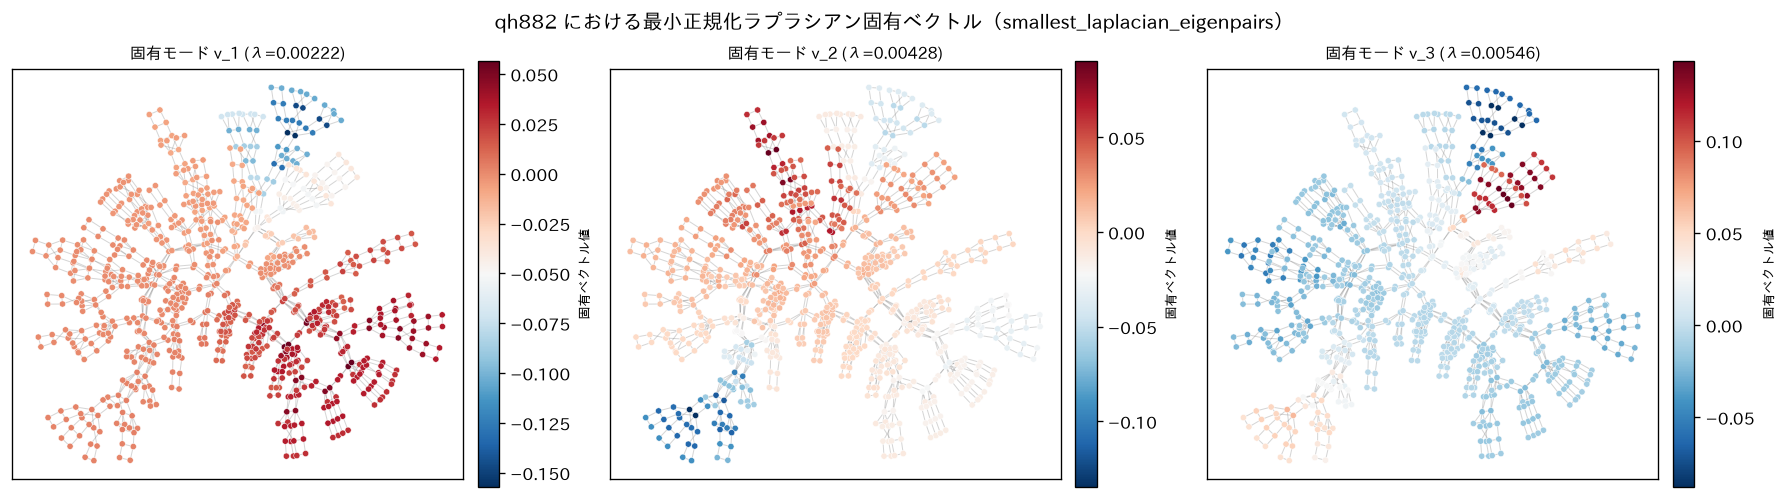

In [ ]:
\
# 1) Anisotropic Laplacian & spectral moment stats on qh882
L_aniso, u_scale = eg.anisotropic_laplacian(g_qh, alpha=0.5, beta=0.0, degree_reg=0.0, reweighted_degree_norm=True)
residual_null = np.linalg.norm(L_aniso.spmv(u_scale))
stats_qh = eg.spectral_moment_stats(g_qh)
print(f"anisotropic_laplacian on qh882: nnz={L_aniso.nnz}, ||L_aniso @ u||_2 = {residual_null:.2e}")
print("spectral_moment_stats(qh882):", {k: round(v, 4) for k, v in stats_qh.items()})

# 2) Smallest Laplacian eigenpairs, diffusion embedding, resistance embedding
lambdas, vecs, inv_sqrt_deg, used_dense = eg.smallest_laplacian_eigenpairs(g_qh, n_modes=8, tol=1e-4, seed=42)
diff_coords, diff_lams, t_used = eg.compute_diffusion_embedding(g_qh, dim=8, p=0.5, seed=42)
res_coords, res_lams = eg.compute_resistance_embedding(g_qh, dim=8, seed=42)

print(f"smallest_laplacian_eigenpairs: shape={vecs.shape}, used_dense_fallback={used_dense}")
print("  lambdas[:6]:", np.round(lambdas[:6], 5))
print(f"compute_diffusion_embedding: shape={diff_coords.shape}, t_used={t_used:.4f}, lambdas[:4]={np.round(diff_lams[:4], 5)}")
print(f"compute_resistance_embedding: shape={res_coords.shape}, lambdas_kept[:4]={np.round(res_lams[:4], 5)}")

# Compute 2D layout of qh882 to visualize eigenvectors 1, 2, 3
l_qh = eg.pivot_mds_init(g_qh, num_pivots=50, seed=42)
eg.SgdSolver.full(g_qh, iterations=60, seed=42).run(l_qh)

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.2))
for mode_idx, ax in enumerate(axes, start=1):
    plot_graph_values(
        g_qh,
        l_qh,
        vecs[:, mode_idx],
        ax=ax,
        cmap="RdBu_r",
        node_size=14,
        title=f"固有モード v_{mode_idx} (λ={lambdas[mode_idx]:.5f})",
        cbar_label="固有ベクトル値",
    )
fig.suptitle("qh882 における最小正規化ラプラシアン固有ベクトル（smallest_laplacian_eigenpairs）", fontsize=12)
plt.tight_layout()
plt.show()

\
## 4. チェビシェフ多項式による $O(|E|)$ 熱核 SpMV と `ChebyshevDogKernel`

密行列の指数関数 $\exp(-t L)$ は $O(N^3)$ を要しますが、チェビシェフ多項式展開（`chebyshev_heat_spmv`, `chebyshev_heat_spmv_matrix`, `adaptive_chebyshev_degree`）を用いれば SpMV の反復だけで $O(\text{degree} \cdot |E|)$ で高精度に近似できます。

さらに、異なる時刻 $t_1 < t_2$ の熱核の差 $\exp(-t_1 L) - \exp(-t_2 L)$ に PSD 射影（`build_regularized_dog_terms`, `project_psd_spectral_filter`）と Johnson-Lindenstrauss (JL) ランダム射影を組み合わせた **`ChebyshevDogKernel`**（および `chebyshev_dog_jl_embedding*`）は、Track B（`GuMapSolver`・`SgdSolver.sparse_barrier_dog`）の高速な近傍構造抽出の中核を担います。

t=0.5: rel_err(deg=10)=4.09e-13, rel_err(deg=20)=4.09e-13, rel_err(deg=40)=4.09e-13
t=2.0: rel_err(deg=10)=1.48e-08, rel_err(deg=20)=4.33e-13, rel_err(deg=40)=4.33e-13
t=8.0: rel_err(deg=10)=7.27e-04, rel_err(deg=20)=3.23e-10, rel_err(deg=40)=2.24e-12
ChebyshevDogKernel: deg_auto(t=8)=58, t1=0.647, t2=2.590, degree=40, delta_psd=0.00e+00, table=(882, 32), psd_terms=2 (h_min=2.66e-01)
chebyshev_dog_jl_embedding shape=(882, 32), matrix version shape=(882, 32), finite=True


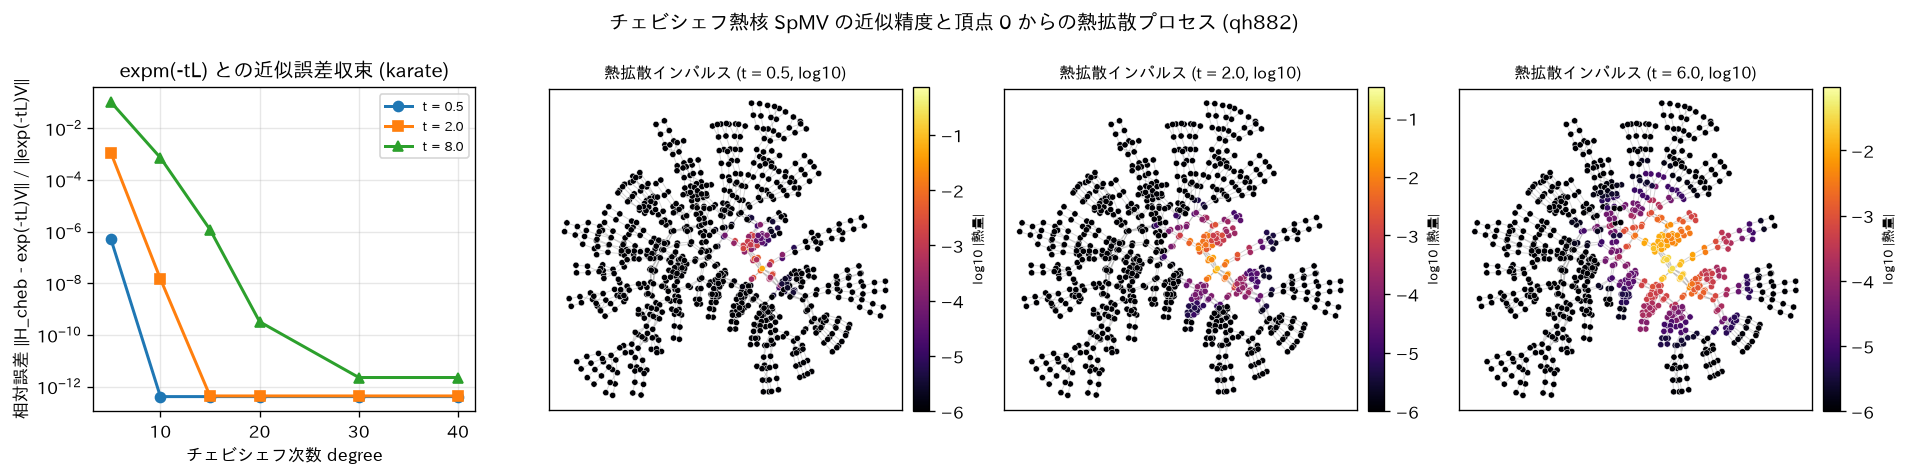

In [ ]:
\
# 1) Compare chebyshev_heat_spmv against exact scipy.linalg.expm(-t * L_sym) on karate
n_kar = g_karate.num_nodes
A_kar = np.zeros((n_kar, n_kar), dtype=np.float64)
ip_kar, idx_kar = g_karate.indptr(), g_karate.indices()
for u in range(n_kar):
    A_kar[u, idx_kar[int(ip_kar[u]) : int(ip_kar[u + 1])]] = 1.0
deg_kar = A_kar.sum(axis=1)
inv_sqrt_d = 1.0 / np.sqrt(np.maximum(deg_kar, 1.0))
L_sym_kar = np.eye(n_kar) - (inv_sqrt_d[:, None] * A_kar) * inv_sqrt_d[None, :]

rng = np.random.default_rng(42)
V_probe = rng.standard_normal((n_kar, 4))
degrees = [5, 10, 15, 20, 30, 40]
times_eval = [0.5, 2.0, 8.0]
err_curves = {}

for t_val in times_eval:
    exact_heat = la.expm(-t_val * L_sym_kar) @ V_probe
    errs = []
    for deg in degrees:
        approx_heat = eg.chebyshev_heat_spmv(g_karate, V_probe, t_val, degree=deg, lambda_max=2.0)
        rel_err = np.linalg.norm(approx_heat - exact_heat) / np.linalg.norm(exact_heat)
        errs.append(float(max(rel_err, 1e-16)))
    err_curves[t_val] = errs
    print(f"t={t_val}: rel_err(deg=10)={errs[1]:.2e}, rel_err(deg=20)={errs[3]:.2e}, rel_err(deg=40)={errs[5]:.2e}")

# 2) ChebyshevDogKernel & bandpass filter primitives
deg_auto = eg.adaptive_chebyshev_degree(8.0)
dog_terms = eg.build_regularized_dog_terms(stats_qh["sigma_lambda_sq"] ** 0.5, beta_floor=0.02)
psd_terms, delta_psd, h_min = eg.project_psd_spectral_filter(dog_terms, lambda_max=2.0, degree=30, eps_psd=1e-4)
dog_kernel = eg.ChebyshevDogKernel(g_qh, n_landmarks=32, jl_dim=32, seed=42)
var_tbl = dog_kernel.varadhan_landmark_table()
print(
    f"ChebyshevDogKernel: deg_auto(t=8)={deg_auto}, t1={dog_kernel.t1:.3f}, t2={dog_kernel.t2:.3f}, "
    f"degree={dog_kernel.degree}, delta_psd={dog_kernel.delta_psd:.2e}, table={var_tbl.shape}, "
    f"psd_terms={len(psd_terms)} (h_min={h_min:.2e})"
)

# 3) Verify chebyshev_heat_spmv_matrix and DoG-JL embeddings
impulse_qh = np.zeros(g_qh.num_nodes, dtype=np.float64)
impulse_qh[0] = 1.0
heat_t05 = eg.chebyshev_heat_spmv_matrix(L_aniso, impulse_qh, 0.5, degree=25, seed=42)
heat_t20 = eg.chebyshev_heat_spmv_matrix(L_aniso, impulse_qh, 2.0, degree=25, seed=42)
heat_t60 = eg.chebyshev_heat_spmv_matrix(L_aniso, impulse_qh, 6.0, degree=30, seed=42)

dog_graph = eg.chebyshev_dog_jl_embedding(g_qh, t1=0.5, t2=4.0, degree=25, jl_dim=32, seed=42)
dog_mat = eg.chebyshev_dog_jl_embedding_matrix(L_aniso, t1=0.5, t2=4.0, degree=25, jl_dim=32, scale_vec=u_scale, seed=42)
print(f"chebyshev_dog_jl_embedding shape={dog_graph.shape}, matrix version shape={dog_mat.shape}, finite={np.isfinite(dog_mat).all()}")

# Plot approximation error decay + impulse heat diffusion snapshots on qh882
fig, axes = plt.subplots(1, 4, figsize=(16.0, 4.0))
for t_val, marker in zip(times_eval, ["o", "s", "^"]):
    axes[0].semilogy(degrees, err_curves[t_val], marker=marker, linewidth=1.8, label=f"t = {t_val}")
axes[0].set_xlabel("チェビシェフ次数 degree")
axes[0].set_ylabel("相対誤差 ||H_cheb - exp(-tL)V|| / ||exp(-tL)V||")
axes[0].set_title("expm(-tL) との近似誤差収束 (karate)")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8)

for ax, h_vec, t_lbl in [
    (axes[1], heat_t05, "t = 0.5"),
    (axes[2], heat_t20, "t = 2.0"),
    (axes[3], heat_t60, "t = 6.0"),
]:
    plot_graph_values(
        g_qh,
        l_qh,
        np.log10(np.maximum(np.abs(h_vec), 1e-6)),
        ax=ax,
        cmap="inferno",
        node_size=14,
        title=f"熱拡散インパルス ({t_lbl}, log10)",
        cbar_label="log10 |熱量|",
    )

fig.suptitle("チェビシェフ熱核 SpMV の近似精度と頂点 0 からの熱拡散プロセス (qh882)", fontsize=12)
plt.tight_layout()
plt.show()

\
## 5. `AmgPcgSolver`: 代数的マルチグリッド PCG と特異ラプラシアン vs SPD 化

`AmgPcgSolver` は、平滑化集約（Smoothed Aggregation）AMG 前処理と共役勾配法（PCG）を組み合わせ、大規模なグラフラプラシアン線形方程式 $A x = b$ を高速に解きます。

### 構築法と重大な数学的注意点
1. **5 種のコンストラクタ**:
   - `AmgPcgSolver(n, indptr, indices, values, ...)` / `AmgPcgSolver.from_csr(...)` / `AmgPcgSolver.from_csr_matrix(mat, ...)`
   - `AmgPcgSolver.from_graph_regularized_laplacian(graph, gamma=1.0, ...)`: $(I + \gamma L_{\mathrm{sym}}) x = b$ を解きます（任意の $\gamma \ge 0$ で厳密に正定値 SPD）。
   - `AmgPcgSolver.from_graph_laplacian(graph, kind="combinatorial"|"symmetric_normalized", shift=0.0, ...)`:
     - **`shift=0.0` のラプラシアンは半正定値（特異行列）** であり、零空間（combinatorial なら定数ベクトル $\mathbf{1}$、symmetric_normalized なら $D^{1/2}\mathbf{1}$）を持ちます。
     - そのため、`shift=0.0` では **右辺 $b$ が零空間と直交する（combinatorial の場合は $\sum_i b_i = 0$ の零平均ベクトル）ときのみ収束** し、非零平均の右辺では $\mathrm{range}(L)$ に属さないため **発散** します。
     - 任意の右辺 $b$ に対して安定に解きたい場合は **`shift > 0`**（例: `shift=0.01`）または **`from_graph_regularized_laplacian`** を使用してください。
2. **対称性バリデーション（`"random_walk"` 非対応）**: AMG-PCG は対称正定値／対称半正定値行列を要求するため、`from_graph_laplacian` のパーサは `"combinatorial"` と `"symmetric_normalized"` のみを受け付け、非対称な `"random_walk"` 等は `ValueError` で拒否されます。

Hierarchy (solver_reg on qh882): num_nodes=882, num_levels=3, coarsest_size=60, operator_complexity=1.193, max_level_nnz=3948

=== Singular vs SPD Laplacian Solve Comparison (qh882) ===
  combinatorial (shift=0, zero-mean b)  : status=converged  iters= 18 rel_res=2.885e-09 converged=True
  combinatorial (shift=0, non-zero b)   : status=completed  iters= 17 rel_res=1.368e+08 converged=False
  sym_norm      (shift=0, non-zero b)   : status=completed  iters= 16 rel_res=2.460e+08 converged=False
  combinatorial (shift=0.01, non-zero b): status=converged  iters= 15 rel_res=3.611e-09 converged=True
  sym_norm      (shift=0.01, non-zero b): status=converged  iters= 13 rel_res=3.327e-09 converged=True
  regularized   (gamma=1.0, non-zero b) : status=converged  iters=  6 rel_res=2.651e-10 converged=True

solve_batch (3 RHS cols): X shape=(882, 3), all_converged=True, max_rel_res=3.643e-10
Expected ValueError for kind='random_walk': unknown Laplacian kind "random_walk"; expected 'combinatorial' 

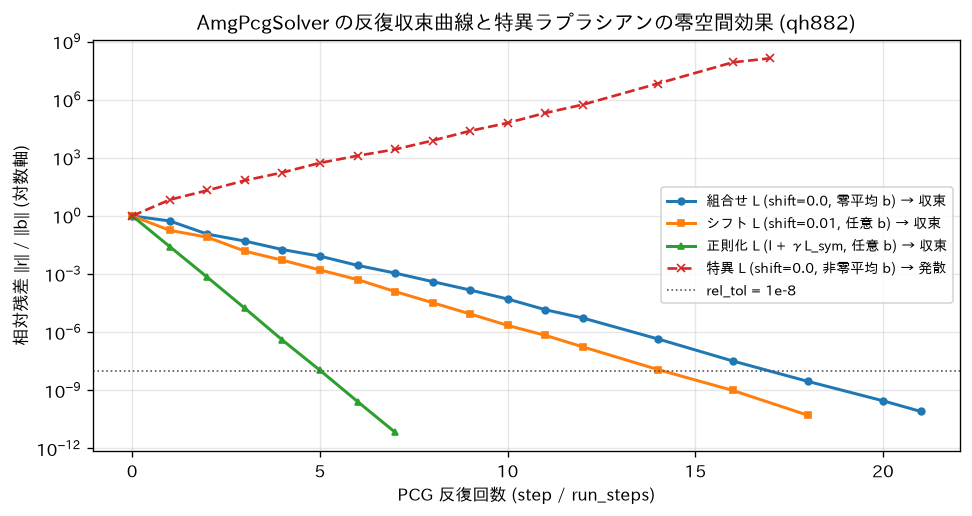

In [ ]:
\
# 1) Compare all 5 constructors & inspect hierarchy properties
ip_k, idx_k, val_k = L_direct.indptr(), L_direct.indices(), L_direct.values()
solver_direct = eg.AmgPcgSolver(n_k, ip_k, idx_k, val_k, rel_tol=1e-8)
solver_csr = eg.AmgPcgSolver.from_csr(n_k, ip_k, idx_k, val_k, rel_tol=1e-8)
solver_mat = eg.AmgPcgSolver.from_csr_matrix(L_direct.scale_and_shift(1.0, 0.05), rel_tol=1e-8)
solver_reg = eg.AmgPcgSolver.from_graph_regularized_laplacian(g_qh, gamma=1.0, rel_tol=1e-8, max_iterations=200)
solver_comb = eg.AmgPcgSolver.from_graph_laplacian(g_qh, kind="combinatorial", shift=0.0, rel_tol=1e-8, max_iterations=100)
solver_comb_shift = eg.AmgPcgSolver.from_graph_laplacian(g_qh, kind="combinatorial", shift=0.01, rel_tol=1e-8, max_iterations=100)
solver_sym_shift = eg.AmgPcgSolver.from_graph_laplacian(g_qh, kind="symmetric_normalized", shift=0.01, rel_tol=1e-8, max_iterations=100)
solver_sym_sing = eg.AmgPcgSolver.from_graph_laplacian(g_qh, kind="symmetric_normalized", shift=0.0, rel_tol=1e-8, max_iterations=60)

print(
    f"Hierarchy (solver_reg on qh882): num_nodes={solver_reg.num_nodes}, num_levels={solver_reg.num_levels}, "
    f"coarsest_size={solver_reg.coarsest_size}, operator_complexity={solver_reg.operator_complexity:.3f}, "
    f"max_level_nnz={solver_reg.max_level_nnz}"
)

# 2) Verify zero-mean RHS vs non-zero-mean RHS on singular vs SPD Laplacians
rng = np.random.default_rng(42)
b_raw = rng.standard_normal(g_qh.num_nodes) + 2.0  # Intentionally non-zero mean
b_zero_mean = b_raw - b_raw.mean()

x_cz, info_cz = solver_comb.solve(b_zero_mean)
x_cn, info_cn = solver_comb.solve(b_raw)
x_ss, info_ss = solver_sym_sing.solve(b_raw)
x_cs, info_cs = solver_comb_shift.solve(b_raw)
x_sn, info_sn = solver_sym_shift.solve(b_raw)
x_rg, info_rg = solver_reg.solve(b_raw)

print("\n=== Singular vs SPD Laplacian Solve Comparison (qh882) ===")
for lbl, info in [
    ("combinatorial (shift=0, zero-mean b)  ", info_cz),
    ("combinatorial (shift=0, non-zero b)   ", info_cn),
    ("sym_norm      (shift=0, non-zero b)   ", info_ss),
    ("combinatorial (shift=0.01, non-zero b)", info_cs),
    ("sym_norm      (shift=0.01, non-zero b)", info_sn),
    ("regularized   (gamma=1.0, non-zero b) ", info_rg),
]:
    print(
        f"  {lbl}: status={info['status']:<10s} iters={info['iterations']:3d} "
        f"rel_res={info['relative_residual']:.3e} converged={info['converged']}"
    )

# 3) Batch solve (solve_batch) & cooperative stepping (start_solve / step / run_steps / run / solution)
B_batch = rng.standard_normal((g_qh.num_nodes, 3))
X_batch, batch_info = solver_reg.solve_batch(B_batch)
print(f"\nsolve_batch (3 RHS cols): X shape={X_batch.shape}, all_converged={batch_info['all_converged']}, max_rel_res={batch_info['max_relative_residual']:.3e}")

# Verify 'random_walk' raises ValueError
try:
    eg.AmgPcgSolver.from_graph_laplacian(g_qh, kind="random_walk")
except ValueError as err:
    print("Expected ValueError for kind='random_walk':", err)

# Track residual convergence across cooperative step() / run_steps()
def trace_amg_convergence(solver: eg.AmgPcgSolver, b: np.ndarray, max_trace_steps: int = 25):
    '''Trace relative residual across cooperative AMG-PCG iterations.'''
    iters = []
    rel_res = []
    st = solver.start_solve(b)
    iters.append(solver.iteration)
    rel_res.append(solver.relative_residual)
    while not solver.is_finished and solver.iteration < max_trace_steps:
        if solver.iteration < 12:
            solver.step()
        else:
            solver.run_steps(2)
        iters.append(solver.iteration)
        rel_res.append(solver.relative_residual)
    if not solver.is_finished and max_trace_steps > 25:
        solver.run()
    return iters, rel_res, solver


it_cz, rr_cz, s_cz = trace_amg_convergence(eg.AmgPcgSolver.from_graph_laplacian(g_qh, "combinatorial", shift=0.0, rel_tol=1e-10, max_iterations=40), b_zero_mean, 35)
it_cn, rr_cn, _ = trace_amg_convergence(eg.AmgPcgSolver.from_graph_laplacian(g_qh, "combinatorial", shift=0.0, rel_tol=1e-10, max_iterations=25), b_raw, 20)
it_cs, rr_cs, _ = trace_amg_convergence(eg.AmgPcgSolver.from_graph_laplacian(g_qh, "combinatorial", shift=0.01, rel_tol=1e-10, max_iterations=40), b_raw, 35)
it_rg, rr_rg, s_rg = trace_amg_convergence(eg.AmgPcgSolver.from_graph_regularized_laplacian(g_qh, gamma=1.0, rel_tol=1e-10, max_iterations=40), b_raw, 35)

# Inspect all solve-state properties on s_rg
sol_rg = s_rg.solution()
print(
    f"Cooperative solve properties: status={s_rg.status!r}, iteration={s_rg.iteration}, "
    f"total_iterations={s_rg.total_iterations}, is_finished={s_rg.is_finished}, "
    f"residual_norm={s_rg.residual_norm:.3e}, relative_residual={s_rg.relative_residual:.3e}, "
    f"converged={s_rg.converged}, sol_shape={sol_rg.shape}"
)

fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.semilogy(it_cz, rr_cz, marker="o", markersize=4, linewidth=1.8, label="組合せ L (shift=0.0, 零平均 b) → 収束")
ax.semilogy(it_cs, rr_cs, marker="s", markersize=4, linewidth=1.8, label="シフト L (shift=0.01, 任意 b) → 収束")
ax.semilogy(it_rg, rr_rg, marker="^", markersize=4, linewidth=1.8, label="正則化 L (I + γL_sym, 任意 b) → 収束")
ax.semilogy(it_cn, rr_cn, marker="x", markersize=5, linewidth=1.6, linestyle="--", color="#d62728", label="特異 L (shift=0.0, 非零平均 b) → 発散")
ax.axhline(1e-8, color="#555555", linestyle=":", linewidth=1.0, label="rel_tol = 1e-8")
ax.set_xlabel("PCG 反復回数 (step / run_steps)")
ax.set_ylabel("相対残差 ||r|| / ||b|| (対数軸)")
ax.set_title("AmgPcgSolver の反復収束曲線と特異ラプラシアンの零空間効果 (qh882)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8.5, loc="best")
plt.tight_layout()
plt.show()

## 6. 有効抵抗（`compute_effective_resistances`）と抵抗曲率フロー（`resistance_curvature_flow`）

グラフを電気抵抗回路と見なしたときの各辺 $e = (u, v)$ の **有効抵抗（Effective Resistance）** $R_{\mathrm{eff}}(u, v)$ は、全木（spanning tree）に含まれる確率や辺のボトルネック重要度を表し、**Foster の定理** により連結成分ごとに $\sum_{e \in E} c_e R_{\mathrm{eff}}(e) = N - \text{num\_components}$ を厳密に満たします。

さらに `resistance_curvature_flow` は、離散抵抗曲率（vertex / link curvature）に基づいて辺長・コンダクタンスを反復更新し、ボトルネック構造の強調や多様体トポロジの判定（NB07）に利用できます。

karate exact ER: num_nodes=34, num_edges=78, num_components=1, foster_sum=33.0000, expected_foster=33.0000, foster_rel_err=2.15e-16, used_exact=True, len=78
karate JL(128) ER: foster_sum=32.8785, foster_rel_err=0.0037, amg_total_iters=128, amg_max_rel_res=2.57e-12, amg_all_converged=True
  to_dict keys: ['num_nodes', 'num_edges', 'num_components', 'foster_sum', 'expected_foster', 'foster_rel_err', 'used_exact', 'amg_total_iterations', 'amg_max_relative_residual', 'amg_all_converged']
  Highest-resistance edge (bridge-like): (0, 11), R_eff=1.0000

RCF (5 steps): mean_link_k=-4.4126, range=[-29.4279, 10.9081], mean_vertex_k=0.0294, range=[-1.6439, 0.5000]
  suggested_geometry='hyperbolic', suggested_manifold='hyperbolic'
  length_graph weighted=True, conductance_graph weighted=True, len(rcf)=78
  to_dict keys count=19, step_history steps=6


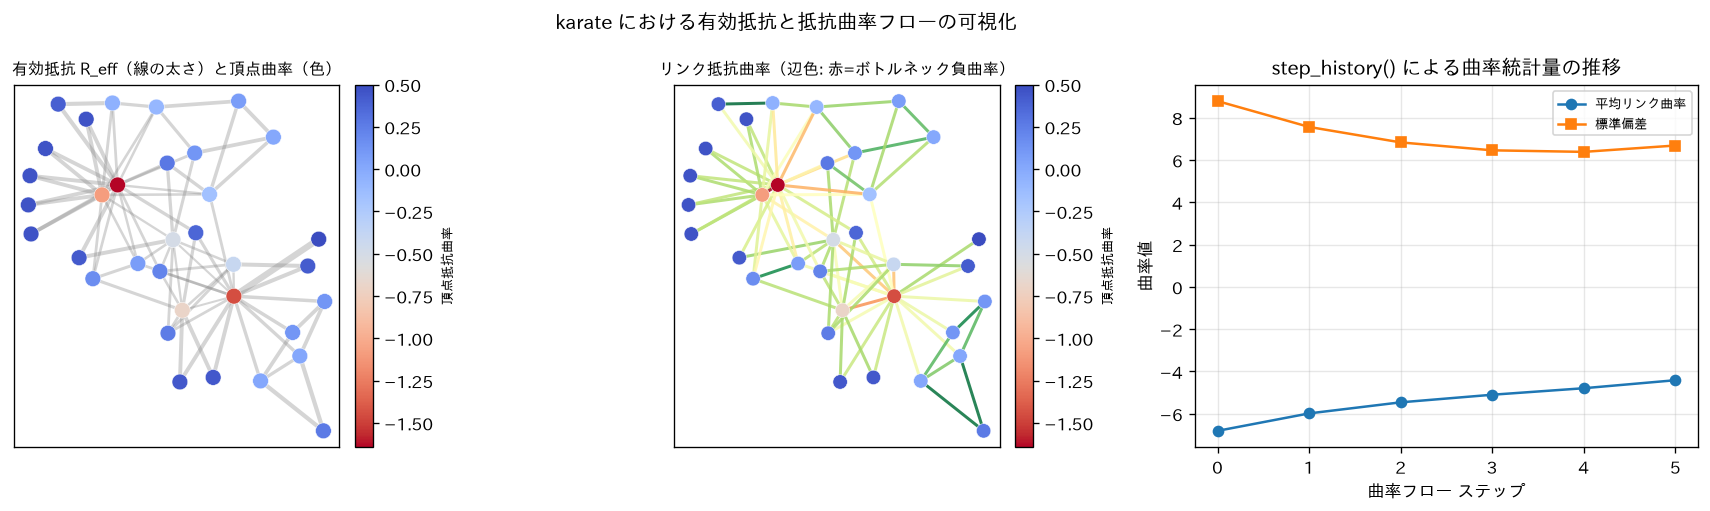

In [ ]:
\
# 1) Compare exact vs JL effective resistances on karate (Foster's theorem check)
er_exact = eg.compute_effective_resistances(g_karate, exact=True)
er_jl = eg.compute_effective_resistances(g_karate, jl_dim=128, seed=42, exact=False)
print(
    f"karate exact ER: num_nodes={er_exact.num_nodes}, num_edges={er_exact.num_edges}, "
    f"num_components={er_exact.num_components}, foster_sum={er_exact.foster_sum:.4f}, "
    f"expected_foster={er_exact.expected_foster:.4f}, foster_rel_err={er_exact.foster_rel_err:.2e}, "
    f"used_exact={er_exact.used_exact}, len={len(er_exact)}"
)
print(
    f"karate JL(128) ER: foster_sum={er_jl.foster_sum:.4f}, foster_rel_err={er_jl.foster_rel_err:.4f}, "
    f"amg_total_iters={er_jl.amg_total_iterations}, amg_max_rel_res={er_jl.amg_max_relative_residual:.2e}, "
    f"amg_all_converged={er_jl.amg_all_converged}"
)
print("  to_dict keys:", list(er_exact.to_dict().keys()))

# Inspect array getters
eu, ev = er_exact.edge_u(), er_exact.edge_v()
elens, conds, reffs = er_exact.edge_lengths(), er_exact.conductances(), er_exact.effective_resistances()
max_r_idx = int(np.argmax(reffs))
print(f"  Highest-resistance edge (bridge-like): ({eu[max_r_idx]}, {ev[max_r_idx]}), R_eff={reffs[max_r_idx]:.4f}")

# 2) Run resistance_curvature_flow on karate and inspect all properties & outputs
rcf_kar = eg.resistance_curvature_flow(g_karate, steps=5, eta=0.15, exact=True, seed=42)
v_curv = rcf_kar.vertex_curvatures()
l_curv = rcf_kar.link_curvatures()
hist = rcf_kar.step_history()
g_len = rcf_kar.length_graph()
g_cond = rcf_kar.conductance_graph()

print(
    f"\nRCF (5 steps): mean_link_k={rcf_kar.mean_link_curvature:.4f}, "
    f"range=[{rcf_kar.min_link_curvature:.4f}, {rcf_kar.max_link_curvature:.4f}], "
    f"mean_vertex_k={rcf_kar.mean_vertex_curvature:.4f}, "
    f"range=[{rcf_kar.min_vertex_curvature:.4f}, {rcf_kar.max_vertex_curvature:.4f}]"
)
print(f"  suggested_geometry={rcf_kar.suggested_geometry!r}, suggested_manifold={rcf_kar.suggested_manifold!r}")
print(f"  length_graph weighted={g_len.is_weighted}, conductance_graph weighted={g_cond.is_weighted}, len(rcf)={len(rcf_kar)}")
print(f"  to_dict keys count={len(rcf_kar.to_dict())}, step_history steps={len(hist)}")

# Visualize effective resistance (edge width) & resistance curvature on karate + RCF evolution
l_kar = eg.pivot_mds_init(g_karate, num_pivots=16, seed=42)
eg.SgdSolver.full(g_karate, iterations=60, seed=42).run(l_kar)

# Map per-edge R_eff and link curvature to unique (u < v) order used by plot_graph_values
edge_reff_map = {(min(int(u), int(v)), max(int(u), int(v))): float(r) for u, v, r in zip(eu, ev, reffs)}
edge_k_map = {(min(int(u), int(v)), max(int(u), int(v))): float(k) for u, v, k in zip(rcf_kar.edge_u(), rcf_kar.edge_v(), l_curv)}

ordered_reffs = []
ordered_curvs = []
for u in range(g_karate.num_nodes):
    for v in idx_kar[int(ip_kar[u]) : int(ip_kar[u + 1])]:
        v_int = int(v)
        if u < v_int:
            ordered_reffs.append(edge_reff_map[(u, v_int)])
            ordered_curvs.append(edge_k_map[(u, v_int)])
ordered_reffs = np.array(ordered_reffs)
ordered_curvs = np.array(ordered_curvs)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))
plot_graph_values(
    g_karate,
    l_kar,
    v_curv,
    ax=axes[0],
    cmap="coolwarm_r",
    node_size=90,
    edge_widths=0.6 + 3.2 * (ordered_reffs / ordered_reffs.max()),
    title="有効抵抗 R_eff（線の太さ）と頂点曲率（色）",
    cbar_label="頂点抵抗曲率",
)
plot_graph_values(
    g_karate,
    l_kar,
    v_curv,
    ax=axes[1],
    cmap="coolwarm_r",
    node_size=75,
    edge_widths=np.full_like(ordered_curvs, 1.8),
    edge_colors=ordered_curvs,
    edge_cmap="RdYlGn",
    title="リンク抵抗曲率（辺色: 赤=ボトルネック負曲率）",
    cbar_label="頂点抵抗曲率",
)

steps_arr = [h["step"] for h in hist]
axes[2].plot(steps_arr, [h["mean_link_curvature"] for h in hist], marker="o", label="平均リンク曲率")
axes[2].plot(steps_arr, [h["std_link_curvature"] for h in hist], marker="s", label="標準偏差")
axes[2].set_xlabel("曲率フロー ステップ")
axes[2].set_ylabel("曲率値")
axes[2].set_title("step_history() による曲率統計量の推移")
axes[2].grid(alpha=0.3)
axes[2].legend(fontsize=8)

fig.suptitle("karate における有効抵抗と抵抗曲率フローの可視化", fontsize=12)
plt.tight_layout()
plt.show()